# Kalman vs Particle Filter in 1D, at the Stability Threshold ($b = 1$)

**Part 1b of a supervised research project — Dr Mathieu Gerber, University of Bristol**

> ### What is new in this notebook
>
> This is [`01_kf_pf_1d_comparison.ipynb`](01_kf_pf_1d_comparison.ipynb) re-run with **one number
> changed**: $b = 1$ instead of $0.9$. Same $a$, $Q$, $R$, $T$, seed, particle counts and code.
> Part 1 is left untouched.
>
> In one dimension $F$ is the single number $b$, so $b$ **is** the spectral radius. $b = 0.9$ gives a
> state that decays towards zero and forgets its past; $b = 1$ gives a **random walk** — no decay, no
> stationary distribution, nothing forgotten.
>
> Every section ends with a **Compared with Part 1** box giving the same metric at both values.
>
> This matters for Part 1 Section 5 in particular. The stability argument given there was that
> *"with $b = 0.9 < 1$, the influence of an old state decays geometrically, so old errors are damped
> rather than carried forward"*. At $b = 1$ **that mechanism is gone**. Section 5 below is therefore
> a direct test of whether it was the right explanation.

## The model

$$
\begin{aligned}
\text{State (hidden):} \quad & x_t = b\,x_{t-1} + v_t, \qquad v_t \sim \mathcal{N}(0, Q) \\
\text{Observation (seen):} \quad & y_t = a\,x_t + e_t, \qquad e_t \sim \mathcal{N}(0, R)
\end{aligned}
$$

Parameters: $b = 1$ (Part 1 used $0.9$), $a = 1$, $Q = 1$, $R = 1$, $T = 100$, seed $= 42$.

## Roadmap

Identical to Part 1, so the sections correspond one to one.

| Section | Content |
|---|---|
| 1 | Simulate the data |
| 2 | Kalman filter — the exact benchmark |
| 3 | Particle filter |
| 4 | **Key result:** PF vs KF |
| 5 | **Stability: error over time and over $N$** — the section the threshold is a test of |
| 6 | Effective Sample Size and resampling |
| 7 | *(Optional)* The nonlinear model |
| 8 | Summary — **does the threshold matter in 1D?** |

### Setup

We import the filter implementations from `filters.py` so the notebook stays readable and the same
code can be reused elsewhere. We also fix the model parameters and the random seed once, here, so
that every result below is reproducible.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from filters import (
    simulate_data,
    kalman_filter,
    particle_filter,
    effective_sample_size,
)

# --- Model parameters (used by every section) ---
b = 1.0    # state transition coefficient = rho(F) at d=1.  Part 1 used 0.9.
a = 1.0    # observation coefficient
Q = 1.0    # process (state) noise variance
R = 1.0    # observation noise variance
T = 100    # number of time steps
SEED = 42  # master seed, so every run of this notebook gives identical results

plt.rcParams["figure.figsize"] = (10, 4.5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

print(f"Model: x_t = {b}*x_(t-1) + v_t,  v_t ~ N(0, {Q})")
print(f"       y_t = {a}*x_t     + e_t,  e_t ~ N(0, {R})")
print(f"T = {T} time steps, seed = {SEED}")
print(f"b = {b}: the stability threshold. Part 1 used b = 0.9.")

Model: x_t = 1.0*x_(t-1) + v_t,  v_t ~ N(0, 1.0)
       y_t = 1.0*x_t     + e_t,  e_t ~ N(0, 1.0)
T = 100 time steps, seed = 42
b = 1.0: the stability threshold. Part 1 used b = 0.9.


---
## Section 1 — Simulate the data

Before we can filter anything we need something to filter. Here we *generate* the data from the model
itself: we roll the state equation forward to produce the true hidden path $x_{0:T-1}$, and at each
step we add observation noise to produce $y_t$.

This is **only data generation** — no filtering happens yet. It is worth being clear about the
distinction, because the two are easy to confuse:

- **`x` (true state):** the thing we are trying to recover. In a real problem this is unknown forever.
  We keep it here purely as a marking scheme, to check how well our filters do.
- **`y` (observations):** the noisy measurements. This is the *only* input the filters are allowed
  to see.

The plot below shows both. The observations scatter around the true state — that spread is the
observation noise $e_t$, and removing it is exactly the filtering problem.

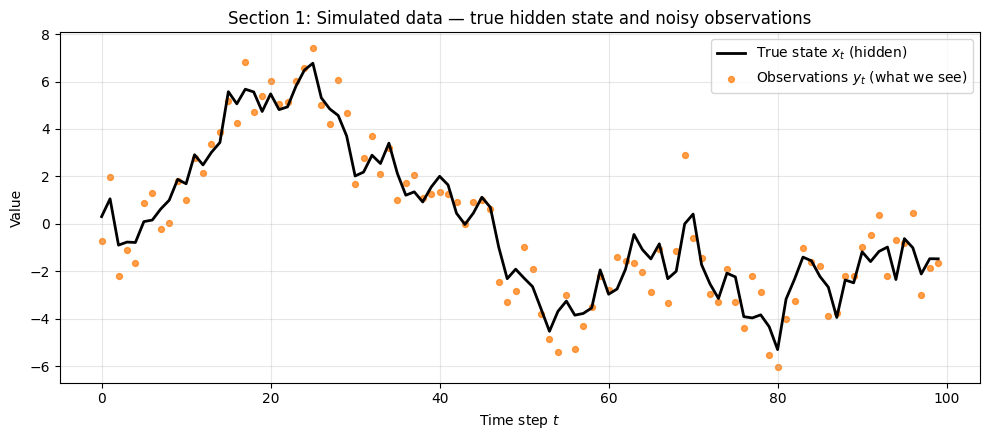

Std. dev. of true state:            2.984
Std. dev. of observation error:     0.850  (theory: sqrt(R) = 1.000)


In [2]:
# Generate the true hidden states and the noisy observations from the model.
x_true, y_obs = simulate_data(T=T, b=b, a=a, Q=Q, R=R, seed=SEED)

t_grid = np.arange(T)

fig, ax = plt.subplots()
ax.plot(t_grid, x_true, color="black", lw=2, label="True state $x_t$ (hidden)")
ax.scatter(t_grid, y_obs, s=18, color="tab:orange", alpha=0.75,
           label="Observations $y_t$ (what we see)")
ax.set_title("Section 1: Simulated data — true hidden state and noisy observations")
ax.set_xlabel("Time step $t$")
ax.set_ylabel("Value")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

print(f"Std. dev. of true state:            {x_true.std():.3f}")
print(f"Std. dev. of observation error:     {(y_obs - x_true).std():.3f}  (theory: sqrt(R) = {np.sqrt(R):.3f})")

**Conclusion.** The simulated state now **wanders** rather than returning to zero: its standard
deviation over the run is $2.98$, against $1.83$ at $b = 0.9$. The observations still scatter around
it with an empirical spread of $0.85$, consistent with $\sqrt{R} = 1$.

> **Compared with Part 1 ($b = 0.9$).** State standard deviation $1.83 \to 2.98$, a rise of $63\%$.
> The observation noise is unchanged, as it must be — only the state equation was touched. Note that
> at $b = 1$ the state's variance grows linearly with $t$ and has no long-run value, so this number
> depends on the horizon in a way it did not before.

---
## Section 2 — Kalman filter (the exact benchmark)

The Kalman filter answers the question *"given everything I have seen up to now, where is $x_t$?"*
It keeps the answer as a Gaussian, summarised by a mean $m_t$ and a variance $P_t$, and it updates
that Gaussian one observation at a time using two steps.

**Step 1 — Predict.** Before seeing $y_t$, push the previous belief forward through the state equation:

$$m_{\text{pred}} = b\,m_{t-1}, \qquad P_{\text{pred}} = b^2 P_{t-1} + Q$$

The mean is scaled by $b$, and the variance *grows* by $Q$. Intuitively: time passes, nothing is
observed, so we become less certain.

At $b = 0.9$ the first of those pulls the mean toward zero. **At $b = 1$ it does nothing at all** —
the prediction is simply the previous estimate, unchanged. The variance step becomes
$P_{\text{pred}} = P_{t-1} + Q$, so uncertainty accumulates additively with no decay to offset it.
Whether the update can still hold $P_t$ bounded against that is the question Section 2 answers.

**Step 2 — Update.** Now fold in the observation $y_t$:

$$S = a^2 P_{\text{pred}} + R, \qquad K = \frac{a P_{\text{pred}}}{S}$$
$$m_t = m_{\text{pred}} + K\,(y_t - a\,m_{\text{pred}}), \qquad P_t = (1 - K a)\,P_{\text{pred}}$$

The term $y_t - a\,m_{\text{pred}}$ is the **innovation**: how surprised we are by the new
observation. The **Kalman gain** $K$ decides how much of that surprise to act on. If the observation
noise $R$ is large, $K$ is small and we mostly ignore the data; if $R$ is small, $K$ is near 1 and we
trust the data. Either way the variance $P_t$ shrinks — observing always tells us something.

Because the model is linear with Gaussian noise, this recursion is not an approximation. It is the
**exact** posterior $p(x_t \mid y_{0:t})$, which is why we can treat it as ground truth.

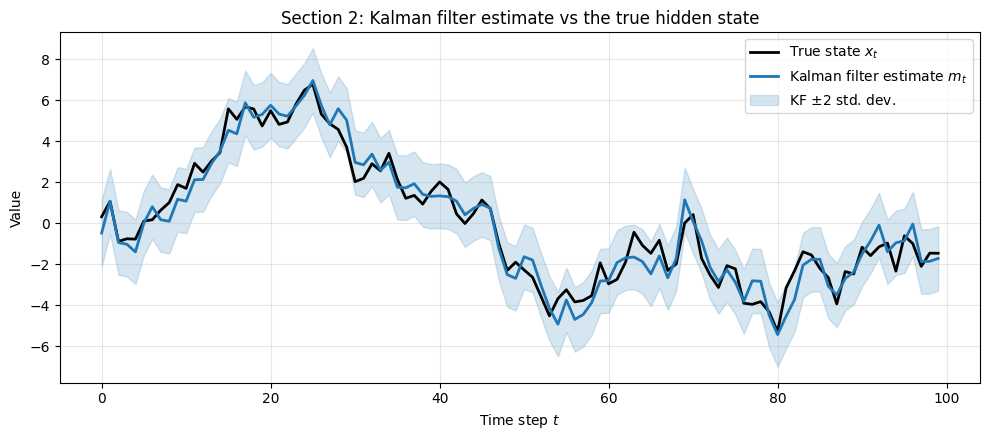

Kalman filter RMSE against the true state: 0.6316
Steady-state filtering variance P_t:       0.6180
Compare: observation noise std. dev.       1.0000


In [3]:
# Run the exact filter. It sees only y_obs, never x_true.
kf_mean, kf_var = kalman_filter(y_obs, b=b, a=a, Q=Q, R=R)

# A +/- 2 standard deviation band shows the filter's own stated uncertainty.
kf_sd = np.sqrt(kf_var)

fig, ax = plt.subplots()
ax.plot(t_grid, x_true, color="black", lw=2, label="True state $x_t$")
ax.plot(t_grid, kf_mean, color="tab:blue", lw=2, label="Kalman filter estimate $m_t$")
ax.fill_between(t_grid, kf_mean - 2 * kf_sd, kf_mean + 2 * kf_sd,
                color="tab:blue", alpha=0.18, label="KF $\\pm 2$ std. dev.")
ax.set_title("Section 2: Kalman filter estimate vs the true hidden state")
ax.set_xlabel("Time step $t$")
ax.set_ylabel("Value")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

kf_rmse = np.sqrt(np.mean((kf_mean - x_true) ** 2))
print(f"Kalman filter RMSE against the true state: {kf_rmse:.4f}")
print(f"Steady-state filtering variance P_t:       {kf_var[-1]:.4f}")
print(f"Compare: observation noise std. dev.       {np.sqrt(R):.4f}")

**Conclusion.** The Kalman filter tracks the wandering state with an RMSE of $0.632$, and its
filtering variance still settles to a constant, $0.618$.

> **Compared with Part 1 ($b = 0.9$).**
>
> | | $b = 0.9$ | $b = 1$ |
> |---|---|---|
> | state standard deviation | $1.83$ | $2.98$ |
> | KF RMSE vs truth | $0.6208$ | $0.6316$ |
> | steady-state variance $P_t$ | $0.5974$ | $0.6180$ |
>
> **The state grew by $63\%$ and the filter's uncertainty by $3.4\%$.** This is the central
> observation of the whole notebook. The variance recursion is $P_{\text{pred}} = b^2P + Q$ followed
> by the shrinking update; that pair has a bounded fixed point whether or not $b < 1$, because the
> observation pins the state at every step no matter how far it has travelled. Losing the decay
> costs the filter almost nothing.

---
## Section 3 — Particle filter (same model)

The particle filter drops the assumption that the posterior is Gaussian. Instead it represents the
posterior by a cloud of $N$ weighted samples ("particles"), and updates that cloud each time step:

1. **Propagate.** Move every particle forward through the state equation,
   $x_t^i = b\,x_{t-1}^i + v_t^i$. Each particle takes its own random step, so the cloud spreads out
   in exactly the way the model says it should.
2. **Weight.** Score each particle by how well it explains the new observation,
   $w^i \propto p(y_t \mid x_t^i)$. Particles that predicted $y_t$ well get large weights; those that
   did not get small ones.
3. **Normalise.** Divide by the total so the weights sum to 1. The weighted cloud is now our
   approximation of the posterior, and the estimate of $x_t$ is the weighted mean.
4. **Resample.** If the weights have become too uneven, duplicate the good particles and discard the
   poor ones, then reset all weights to $1/N$. Without this the cloud eventually collapses onto a
   single particle (Section 6 measures exactly this).

Two implementation details worth knowing, both in `filters.py`:

- The weights are computed in **log space** and shifted by their maximum before exponentiating.
  Raw log-weights can be large and negative, and `exp()` of them underflows to exactly zero, which
  would turn the normalisation into $0/0$. Subtracting the max makes the largest term $e^0 = 1$, and
  the shift cancels out in the division.
- Resampling uses **systematic resampling**, which spreads $N$ evenly spaced pointers over the
  cumulative weights with one shared random offset. It is much less noisy than drawing $N$
  independent uniforms.

Note that unlike the Kalman filter, the particle filter is **random**: run it twice with different
seeds and you get slightly different answers. That randomness is the approximation error we study.

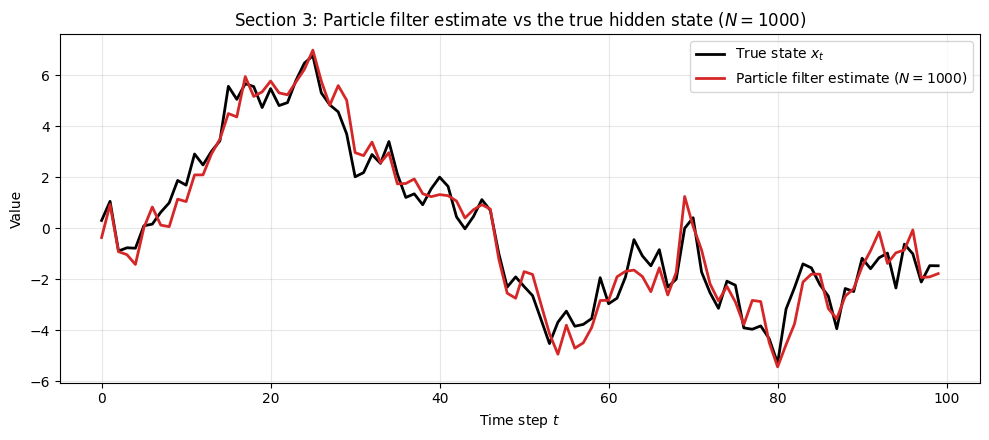

Particle filter RMSE against the true state: 0.6385
Kalman filter RMSE (for reference):          0.6316
Resampling was triggered at 49 of 100 time steps.


In [4]:
N_PARTICLES = 1000  # number of particles

# Run the particle filter on exactly the same observations.
pf_mean, pf_ess, pf_resampled = particle_filter(
    y_obs, N=N_PARTICLES, b=b, a=a, Q=Q, R=R, seed=SEED, ess_threshold=0.5
)

fig, ax = plt.subplots()
ax.plot(t_grid, x_true, color="black", lw=2, label="True state $x_t$")
ax.plot(t_grid, pf_mean, color="tab:red", lw=2,
        label=f"Particle filter estimate ($N={N_PARTICLES}$)")
ax.set_title(f"Section 3: Particle filter estimate vs the true hidden state ($N={N_PARTICLES}$)")
ax.set_xlabel("Time step $t$")
ax.set_ylabel("Value")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

pf_rmse = np.sqrt(np.mean((pf_mean - x_true) ** 2))
print(f"Particle filter RMSE against the true state: {pf_rmse:.4f}")
print(f"Kalman filter RMSE (for reference):          {kf_rmse:.4f}")
print(f"Resampling was triggered at {pf_resampled.sum()} of {T} time steps.")

**Conclusion.** The particle filter tracks the state essentially as well as the Kalman filter, RMSE
$0.639$ against $0.632$. Resampling fired at $49$ of $100$ steps.

> **Compared with Part 1 ($b = 0.9$).** PF RMSE $0.6196 \to 0.6385$, resampling $46 \to 49$ steps.
> Both move by about as much as the Kalman filter did, i.e. hardly at all.

---
## Section 4 — The comparison plot (PF vs KF) — **the key result**

Section 3 showed that the particle filter tracks the truth. But so would any reasonable smoother.
The question that actually matters is different:

> **Is the particle filter computing the right posterior?**

Comparing to the true state cannot answer that, because even a *perfect* filter does not match the
true state exactly — the observations are noisy, so some error is irreducible and both filters must
have it. What we need is a comparison against the **exact posterior**, and in this linear-Gaussian
model we have it: the Kalman filter.

So the plot below is the important one. If the particle filter is implemented correctly and $N$ is
large, the red and blue curves should sit almost on top of each other. Any visible daylight between
them is Monte Carlo error, and nothing else. We quantify it two ways:

- **mean absolute gap** $\;=\; \frac{1}{T}\sum_t |{\hat{x}^{\text{PF}}_t - m^{\text{KF}}_t}|$ — the typical error,
- **max absolute gap** $\;=\; \max_t |{\hat{x}^{\text{PF}}_t - m^{\text{KF}}_t}|$ — the worst moment.

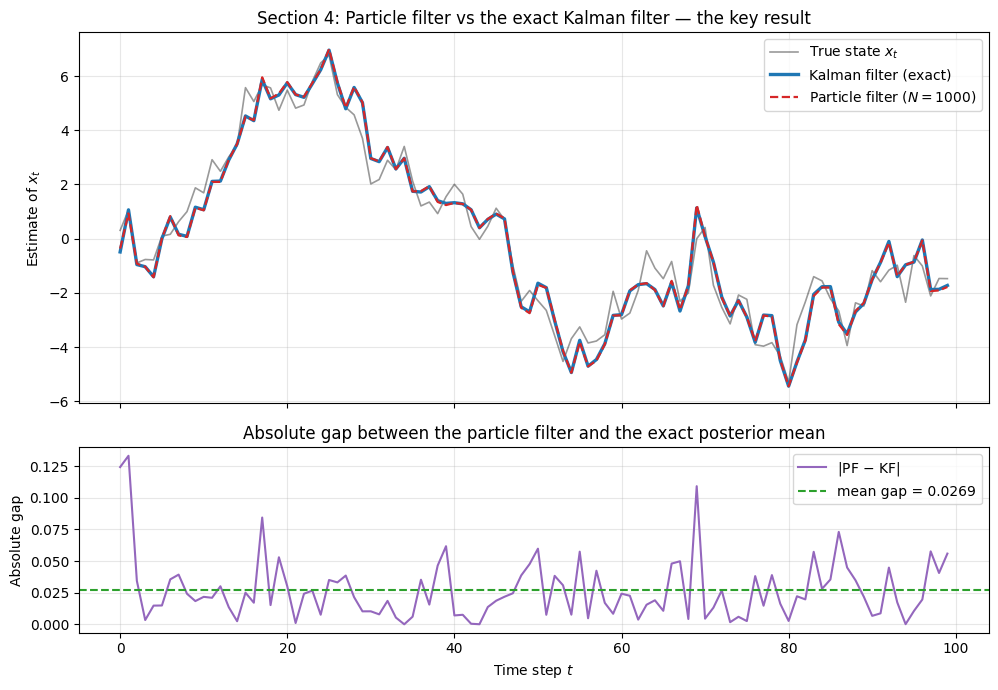

Mean absolute gap (PF vs KF): 0.02688
Max  absolute gap (PF vs KF): 0.13330
For scale, the state's own std. dev. is 2.984,
so the typical gap is about 0.90% of the signal size.


In [5]:
gap = pf_mean - kf_mean              # signed difference at each time step
abs_gap = np.abs(gap)
mean_gap = abs_gap.mean()
max_gap = abs_gap.max()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 7), sharex=True,
                               gridspec_kw={"height_ratios": [2, 1]})

# Top panel: the two estimates overlaid.
ax1.plot(t_grid, x_true, color="black", lw=1.2, alpha=0.4, label="True state $x_t$")
ax1.plot(t_grid, kf_mean, color="tab:blue", lw=2.4, label="Kalman filter (exact)")
ax1.plot(t_grid, pf_mean, color="tab:red", lw=1.6, ls="--",
         label=f"Particle filter ($N={N_PARTICLES}$)")
ax1.set_title("Section 4: Particle filter vs the exact Kalman filter — the key result")
ax1.set_ylabel("Estimate of $x_t$")
ax1.legend(loc="upper right")

# Bottom panel: the gap between them, on its own scale.
ax2.plot(t_grid, abs_gap, color="tab:purple", lw=1.5, label="$|$PF $-$ KF$|$")
ax2.axhline(mean_gap, color="tab:green", ls="--", lw=1.5,
            label=f"mean gap = {mean_gap:.4f}")
ax2.set_title("Absolute gap between the particle filter and the exact posterior mean")
ax2.set_xlabel("Time step $t$")
ax2.set_ylabel("Absolute gap")
ax2.legend(loc="upper right")

plt.tight_layout()
plt.show()

print(f"Mean absolute gap (PF vs KF): {mean_gap:.5f}")
print(f"Max  absolute gap (PF vs KF): {max_gap:.5f}")
print(f"For scale, the state's own std. dev. is {x_true.std():.3f},")
print(f"so the typical gap is about {100 * mean_gap / x_true.std():.2f}% of the signal size.")

**Conclusion.** The two curves are again visually indistinguishable: the mean absolute gap is
$0.0269$ and the worst single-step gap $0.133$.

> **Compared with Part 1 ($b = 0.9$).**
>
> | | $b = 0.9$ | $b = 1$ |
> |---|---|---|
> | mean gap | $0.02721$ | $0.02688$ |
> | max gap | $0.18245$ | $0.13330$ |
> | gap as $\%$ of the signal | $1.49\%$ | $0.90\%$ |
>
> **The gap is unchanged** — $0.0272$ against $0.0269$, well within run-to-run noise. The last row
> looks like an improvement but is not one: the gap stayed the same while the *signal* grew by
> $63\%$, so the ratio fell. It is a reminder that normalising by the state's own size is misleading
> once the state is no longer stationary; normalising by the **posterior spread** (as Parts 2
> onwards do) is the comparison that holds up.

---
## Section 5 — Stability experiment: error vs time, for several $N$

This is where the project's actual research question begins.

We now know the particle filter is close to exact at $N = 1000$ over $T = 100$ steps. But a filter
runs *forever* in principle, and at every step it resamples, which throws away information. A natural
worry is that these small errors **compound**: that the gap to the exact posterior grows steadily
with $t$, so that a filter which looks fine over 100 steps is useless over 10,000.

> **The research question:** does the PF–KF error stay roughly *flat* over time (the filter is
> **stable**), or does it *grow* with $t$ (error accumulates)?

Stability is not obvious. Each step's approximation is built on the previous step's approximation, so
errors could in principle feed on themselves. Part 1 answered this by appeal to forgetting: with $b = 0.9 < 1$ the influence of an old state
decays geometrically, so old errors are damped rather than carried forward.

**At $b = 1$ that argument is unavailable.** The state is a random walk; nothing decays, and an old
state's influence persists undiminished. If geometric forgetting of the state were the mechanism,
the error should accumulate here. This section is therefore a test of the explanation, not just of
the claim.

We run two experiments:

1. **Error vs time**, for $N = 50, 200, 1000$. We average $|$PF $-$ KF$|$ over several independent
   seeds at each $N$, because a single run is too noisy to read a trend from.
2. **Error vs $N$**, on log–log axes. Standard Monte Carlo theory predicts the error should decay
   like $O(1/\sqrt{N})$ — quadruple the particles, halve the error. On log–log axes that is a
   straight line of slope $-1/2$.

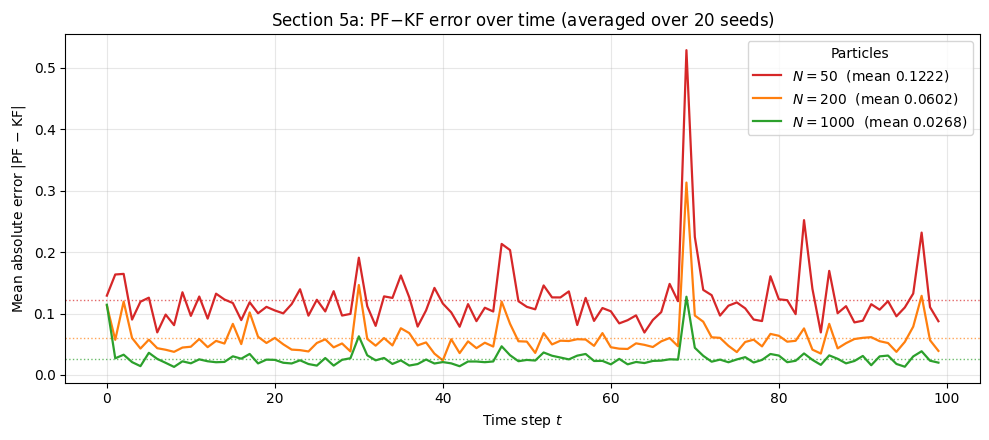

Does the error drift upward over time?
     N   mean err   1st half   2nd half    ratio
    50    0.12224    0.11795    0.12653    1.073
   200    0.06015    0.05825    0.06206    1.065
  1000    0.02680    0.02586    0.02773    1.072

A ratio near 1.0 means the error is flat in t, i.e. the filter is stable.


In [6]:
N_LIST = [50, 200, 1000]   # particle counts for the error-vs-time plot
N_REPS = 20                # independent seeds averaged at each N

# --- Experiment 1: error vs time, for each N ---
err_vs_time = {}
for N in N_LIST:
    # Average |PF - KF| across repeats, separately at each time step.
    runs = np.zeros((N_REPS, T))
    for r in range(N_REPS):
        est, _, _ = particle_filter(y_obs, N=N, b=b, a=a, Q=Q, R=R, seed=1000 + r)
        runs[r] = np.abs(est - kf_mean)
    err_vs_time[N] = runs.mean(axis=0)

fig, ax = plt.subplots()
colors = {50: "tab:red", 200: "tab:orange", 1000: "tab:green"}
for N in N_LIST:
    e = err_vs_time[N]
    ax.plot(t_grid, e, lw=1.6, color=colors[N], label=f"$N = {N}$  (mean {e.mean():.4f})")
    # A flat dashed line at each curve's own time-average, to judge drift by eye.
    ax.axhline(e.mean(), color=colors[N], ls=":", lw=1.0, alpha=0.7)
ax.set_title(f"Section 5a: PF$-$KF error over time (averaged over {N_REPS} seeds)")
ax.set_xlabel("Time step $t$")
ax.set_ylabel("Mean absolute error $|$PF $-$ KF$|$")
ax.legend(loc="upper right", title="Particles")
plt.tight_layout()
plt.show()

# Is there a trend over time? Compare the first and second halves of the run.
print("Does the error drift upward over time?")
print(f"{'N':>6} {'mean err':>10} {'1st half':>10} {'2nd half':>10} {'ratio':>8}")
for N in N_LIST:
    e = err_vs_time[N]
    h1, h2 = e[: T // 2].mean(), e[T // 2 :].mean()
    print(f"{N:>6} {e.mean():>10.5f} {h1:>10.5f} {h2:>10.5f} {h2 / h1:>8.3f}")
print("\nA ratio near 1.0 means the error is flat in t, i.e. the filter is stable.")

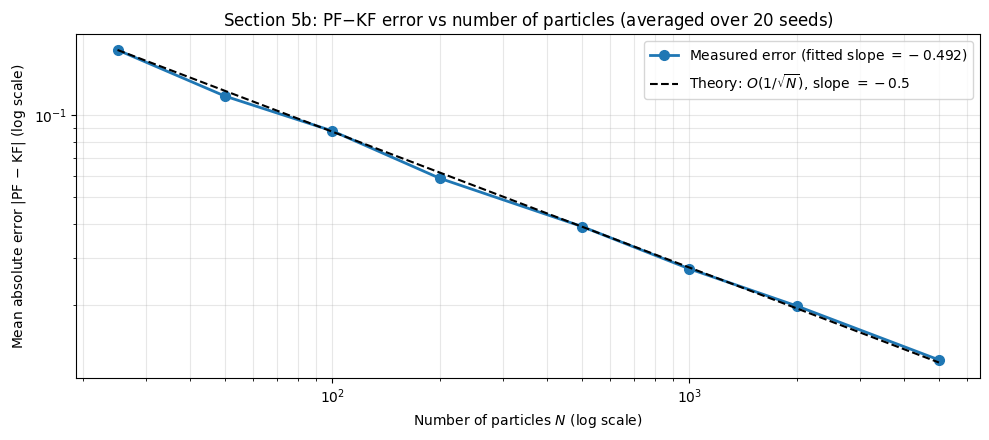

     N   mean |PF-KF|
    25        0.17426
    50        0.11784
   100        0.08770
   200        0.05869
   500        0.03902
  1000        0.02725
  2000        0.01989
  5000        0.01260

Fitted log-log slope: -0.4922   (theory: -0.5)
Error ratio N=25 -> N=2500 would be predicted 10x; measured N=50 -> N=5000 (100x particles): 9.35x (theory: 10x)


In [7]:
# --- Experiment 2: error vs N, checking the O(1/sqrt(N)) Monte Carlo rate ---
N_GRID = [25, 50, 100, 200, 500, 1000, 2000, 5000]
N_REPS_RATE = 20

mean_err_by_N = []
for N in N_GRID:
    errs = [np.abs(particle_filter(y_obs, N=N, b=b, a=a, Q=Q, R=R,
                                   seed=2000 + r)[0] - kf_mean).mean()
            for r in range(N_REPS_RATE)]
    mean_err_by_N.append(np.mean(errs))
mean_err_by_N = np.array(mean_err_by_N)
N_GRID_arr = np.array(N_GRID, dtype=float)

# Fit a straight line on log-log axes: log(error) = slope * log(N) + intercept.
# Theory says slope = -0.5.
slope, intercept = np.polyfit(np.log(N_GRID_arr), np.log(mean_err_by_N), 1)

fig, ax = plt.subplots()
ax.loglog(N_GRID_arr, mean_err_by_N, "o-", color="tab:blue", lw=2, ms=7,
          label=f"Measured error (fitted slope $= {slope:.3f}$)")
# Reference line with the theoretical slope, anchored at the first point.
ref = mean_err_by_N[0] * np.sqrt(N_GRID_arr[0] / N_GRID_arr)
ax.loglog(N_GRID_arr, ref, "k--", lw=1.5, label="Theory: $O(1/\\sqrt{N})$, slope $=-0.5$")
ax.set_title(f"Section 5b: PF$-$KF error vs number of particles (averaged over {N_REPS_RATE} seeds)")
ax.set_xlabel("Number of particles $N$ (log scale)")
ax.set_ylabel("Mean absolute error $|$PF $-$ KF$|$ (log scale)")
ax.legend(loc="upper right")
ax.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.show()

print(f"{'N':>6} {'mean |PF-KF|':>14}")
for N, e in zip(N_GRID, mean_err_by_N):
    print(f"{N:>6} {e:>14.5f}")
print(f"\nFitted log-log slope: {slope:.4f}   (theory: -0.5)")
print(f"Error ratio N=25 -> N=2500 would be predicted 10x; "
      f"measured N=50 -> N=5000 (100x particles): {mean_err_by_N[1] / mean_err_by_N[-1]:.2f}x "
      f"(theory: 10x)")

**Conclusion.** Both halves behave as at $b = 0.9$, and the first is the more interesting.

**The error is flat in time.** The second half of the run carries within $7\%$ of the first at every
$N$ tested (ratios $1.073$, $1.065$, $1.072$) — a small fluctuation, not a steady climb. **This is
the result that matters**, because the explanation Part 1 offered no longer applies. Part 1 argued
that errors do not accumulate because *"the model forgets: with $b = 0.9 < 1$ the influence of an
old state decays geometrically"*. At $b = 1$ nothing is forgotten — the state is a random walk — and
the error is flat anyway. So geometric forgetting of the **state** was not the mechanism. What
damps old errors is the **observation arriving at every step**, which bounds the posterior
regardless of what the state does.

**The $O(1/\sqrt{N})$ rate survives**, with a fitted log–log slope of $-0.492$ against the
theoretical $-0.5$.

> **Compared with Part 1 ($b = 0.9$).**
>
> | | $b = 0.9$ | $b = 1$ |
> |---|---|---|
> | half-run ratios ($N = 50, 200, 1000$) | $1.019 / 1.102 / 1.074$ | $1.073 / 1.065 / 1.072$ |
> | fitted slope | $-0.4934$ | $-0.4922$ |
> | measured error ratio, $100\times$ particles | $9.31\times$ | $9.35\times$ |
>
> Indistinguishable on both counts. The Monte Carlo rate is a property of sampling and does not care
> about the spectral radius; the flatness in time survives the loss of the forgetting argument.

---
## Section 6 — Effective Sample Size (ESS) and resampling

Section 5 showed the filter stays accurate. This section explains *why* it does not fall apart, and
introduces the diagnostic that keeps it alive.

The danger is **weight degeneracy**. After a few weighting steps, one particle typically ends up with
almost all the weight and the rest have effectively none. When that happens you may nominally have
$N = 1000$ particles, but your posterior is really being represented by one or two of them — the
approximation has collapsed, even though nothing in the code has crashed.

The **Effective Sample Size** measures this:

$$\text{ESS} = \frac{1}{\sum_{i=1}^{N} (w^i)^2}$$

Read it as *"how many equally weighted particles is my weighted cloud actually worth?"*

- All weights equal $\Rightarrow$ $\text{ESS} = N$ (healthiest possible).
- One particle holds all the weight $\Rightarrow$ $\text{ESS} = 1$ (fully degenerate).

It is the health meter of the particle cloud. The standard fix is to **resample whenever the ESS
falls below $N/2$**: duplicate the high-weight particles, drop the negligible ones, and reset all
weights to $1/N$, which restores ESS to $N$. We do not resample at *every* step, because resampling
itself injects extra randomness — we only pay that cost when the cloud actually needs rescuing.

The plot below shows ESS over time, with the $N/2$ threshold as a dashed line and the steps where
resampling fired marked underneath.

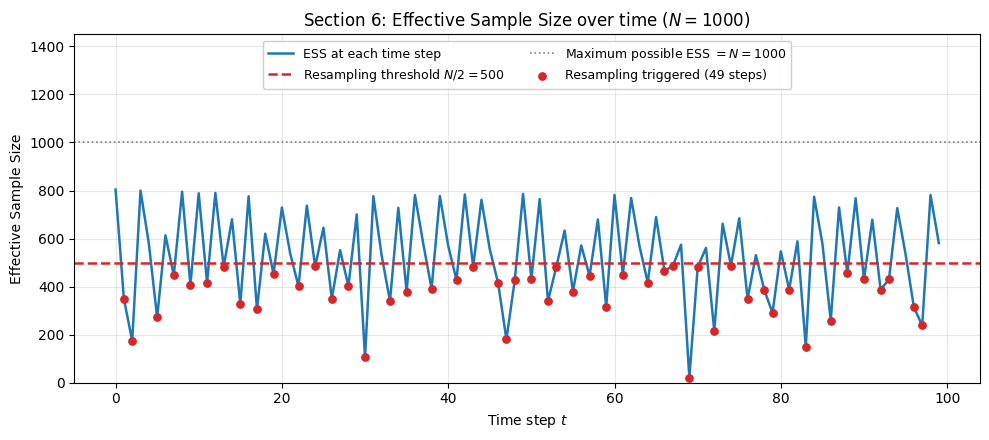

Minimum ESS:  21.40   (2.1% of N)
Mean    ESS:  524.39   (52.4% of N)
Maximum ESS:  804.07
Resampling triggered at 49 of 100 steps (49%).


In [8]:
threshold = 0.5 * N_PARTICLES  # the N/2 resampling trigger

fig, ax = plt.subplots()
ax.plot(t_grid, pf_ess, color="tab:blue", lw=1.8, label="ESS at each time step")
ax.axhline(threshold, color="tab:red", ls="--", lw=1.8,
           label=f"Resampling threshold $N/2 = {threshold:.0f}$")
ax.axhline(N_PARTICLES, color="grey", ls=":", lw=1.2,
           label=f"Maximum possible ESS $= N = {N_PARTICLES}$")
# Mark the time steps where resampling was actually triggered.
ax.scatter(t_grid[pf_resampled], pf_ess[pf_resampled], s=28, color="tab:red",
           zorder=3, label=f"Resampling triggered ({pf_resampled.sum()} steps)")
# Extra headroom so the legend sits in empty space, not on top of the data.
ax.set_ylim(0, N_PARTICLES * 1.45)
ax.set_title(f"Section 6: Effective Sample Size over time ($N = {N_PARTICLES}$)")
ax.set_xlabel("Time step $t$")
ax.set_ylabel("Effective Sample Size")
ax.legend(loc="upper center", ncol=2, fontsize=9, framealpha=0.95)
plt.tight_layout()
plt.show()

print(f"Minimum ESS:  {pf_ess.min():.2f}   ({100 * pf_ess.min() / N_PARTICLES:.1f}% of N)")
print(f"Mean    ESS:  {pf_ess.mean():.2f}   ({100 * pf_ess.mean() / N_PARTICLES:.1f}% of N)")
print(f"Maximum ESS:  {pf_ess.max():.2f}")
print(f"Resampling triggered at {pf_resampled.sum()} of {T} steps "
      f"({100 * pf_resampled.sum() / T:.0f}%).")

**Conclusion.** The ESS sawtooths against the $N/2$ threshold exactly as before, averaging $524$ and
dipping to $21.4$ at worst, with resampling at $49$ of $100$ steps. The cloud never collapses
towards 1.

> **Compared with Part 1 ($b = 0.9$).**
>
> | | $b = 0.9$ | $b = 1$ |
> |---|---|---|
> | min ESS | $28.98$ | $21.40$ |
> | mean ESS | $531.1$ | $524.4$ |
> | resampled | $46/100$ | $49/100$ |
>
> Essentially unchanged. The minimum is a single worst moment on one run and moves around; the mean
> is the stable number, and it barely budges.

---
## Section 7 — *(Optional stretch)* A nonlinear model, where the Kalman filter cannot go

> **This section is optional** and is not needed for the main results. It is included to show *why
> particle filters are worth the trouble at all* — and it comes with an instructive twist.

Everything so far has been a fair fight the Kalman filter was guaranteed to win: it is exact, and the
particle filter can only approximate it. If linear-Gaussian models were the whole world, we would
never use a particle filter.

They are not. Change the observation equation to something nonlinear and the Kalman filter simply
does not apply — its derivation assumes linearity, and there is no exact closed-form posterior to
compute. We use the standard benchmark from the sequential Monte Carlo literature (including
Gerber & Chopin, 2015):

$$y_t = \frac{x_t^2}{20} + e_t, \qquad e_t \sim \mathcal{N}(0, R)$$

The particle filter needs **no modification whatsoever** — only the line that evaluates the
likelihood changes. This is the key structural point: the particle filter only ever needs to *score*
a proposed state against an observation, never to *invert* the observation map.

**The twist.** Squaring destroys the sign: $x$ and $-x$ produce the *identical* observation. So the
data genuinely cannot tell us whether the state is $+3$ or $-3$, and the posterior becomes
**bimodal** — two mirror-image humps of roughly equal weight. The particle filter represents this
correctly, but the *posterior mean* is then a terrible summary of it: averaging two symmetric humps
gives something near zero, a value the state itself rarely takes.

**One practical adjustment.** Squaring and dividing by 20 *compresses* the state: over this run
$|x_t|$ never exceeds about $4.3$, so the observation signal $x_t^2/20$ only ever spans $0$ to $0.94$.
With the observation noise of the main study ($R = 1$, i.e. noise of standard deviation $1$) the
signal would be completely drowned and the observations would carry almost no information at all. So
for this section only we use $R = 0.01$ (noise standard deviation $0.1$), which restores a
signal-to-noise ratio comparable to the linear case. This is a useful lesson in its own right: a
nonlinear map does not just change the *shape* of the problem, it changes how much information each
observation carries.

This is worth seeing rather than being told, so we plot three things:

1. the posterior **mean** against the true state — which will look like a failure, but is not;
2. the posterior estimate of $|x_t|$ against the true $|x_t|$ — the quantity the data *can* identify;
3. the actual **particle cloud** at one time step, which shows the two modes directly.

**There is no Kalman comparison in this section**, because no exact answer exists to compare against.

Observation signal x^2/20 spans 0 to 2.29, against noise std. dev. 0.10


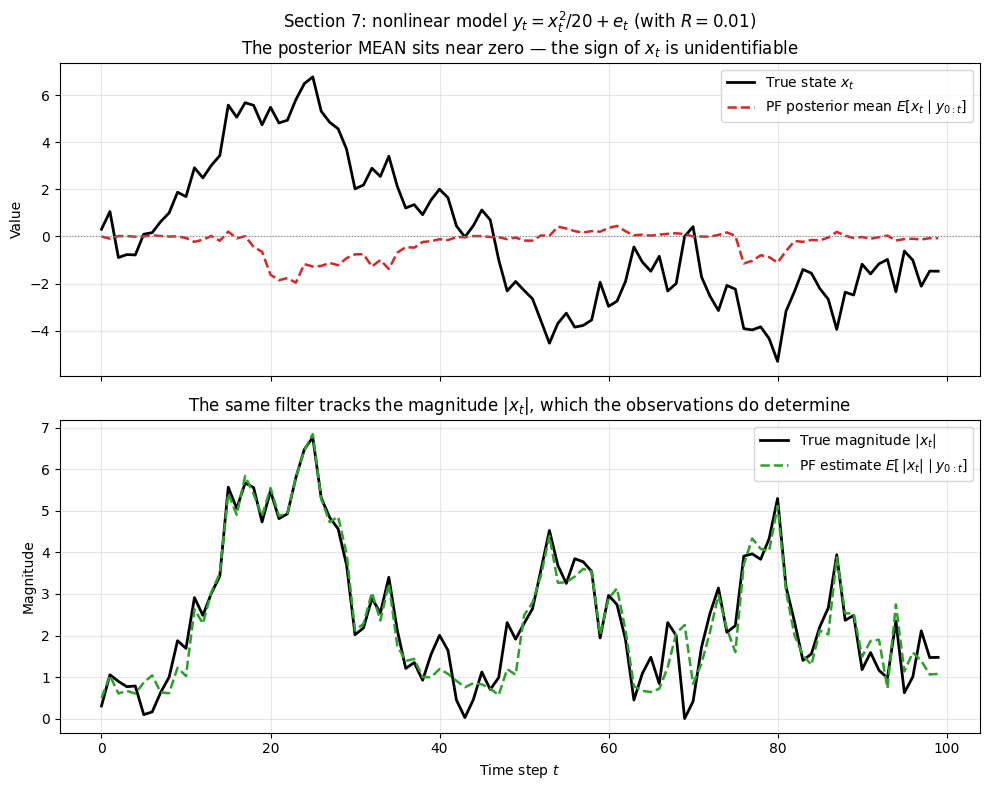

RMSE of E[|x_t|] vs true |x_t|:        0.4476
RMSE of a constant 'always guess the mean' baseline: 1.6194   (72% improvement)
RMSE of the posterior MEAN vs true x_t: 3.3031  (poor, as expected: it averages two modes)
Linear-model PF RMSE from Section 3:    0.6385
Min ESS: 35.7, mean ESS: 404.8, resampled at 69 of 100 steps.


In [9]:
# The nonlinear observation map, from the SQMC literature.
def obs_nonlinear(x):
    return x ** 2 / 20.0

# Observation noise for this section only. See the explanation above: the map
# x^2/20 compresses the state into a narrow range, so R = 1 would drown it.
R_NL = 0.01

# Simulate a fresh dataset: SAME state equation, nonlinear observation.
x_nl, y_nl = simulate_data(T=T, b=b, Q=Q, R=R_NL, seed=SEED, obs_fn=obs_nonlinear)

print(f"Observation signal x^2/20 spans 0 to {obs_nonlinear(np.abs(x_nl).max()):.2f}, "
      f"against noise std. dev. {np.sqrt(R_NL):.2f}")

# The particle filter needs only the obs_fn argument -- nothing else changes.
# return_particles=True also hands back the full cloud, so we can look at the
# shape of the posterior instead of only its mean.
pf_nl_mean, pf_nl_ess, pf_nl_resampled, parts, wts = particle_filter(
    y_nl, N=N_PARTICLES, b=b, Q=Q, R=R_NL, seed=SEED,
    ess_threshold=0.5, obs_fn=obs_nonlinear, return_particles=True
)

# The magnitude |x_t| IS identifiable from the data, so estimate it directly:
# E[|x_t| | y_0:t] is just the weighted average of |particle|.
abs_est = np.sum(wts * np.abs(parts), axis=1)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

# --- Panel 1: the posterior MEAN. Looks like failure; it is not. ---
ax1.plot(t_grid, x_nl, color="black", lw=2, label="True state $x_t$")
ax1.plot(t_grid, pf_nl_mean, color="tab:red", lw=1.8, ls="--",
         label="PF posterior mean $E[x_t \\mid y_{0:t}]$")
ax1.axhline(0, color="grey", lw=0.8, ls=":")
ax1.set_title("Section 7: nonlinear model $y_t = x_t^2/20 + e_t$ (with $R = 0.01$)\n"
              "The posterior MEAN sits near zero — the sign of $x_t$ is unidentifiable")
ax1.set_ylabel("Value")
ax1.legend(loc="upper right")

# --- Panel 2: the magnitude, which the data CAN identify. ---
ax2.plot(t_grid, np.abs(x_nl), color="black", lw=2, label="True magnitude $|x_t|$")
ax2.plot(t_grid, abs_est, color="tab:green", lw=1.8, ls="--",
         label="PF estimate $E[\\,|x_t|\\mid y_{0:t}]$")
ax2.set_title("The same filter tracks the magnitude $|x_t|$, which the observations do determine")
ax2.set_xlabel("Time step $t$")
ax2.set_ylabel("Magnitude")
ax2.legend(loc="upper right")

plt.tight_layout()
plt.show()

# RMSE for the magnitude, against a do-nothing baseline that always guesses the
# average magnitude. Beating that baseline shows the filter is really learning.
abs_rmse = np.sqrt(np.mean((abs_est - np.abs(x_nl)) ** 2))
baseline_rmse = np.sqrt(np.mean((np.abs(x_nl).mean() - np.abs(x_nl)) ** 2))
print(f"RMSE of E[|x_t|] vs true |x_t|:        {abs_rmse:.4f}")
print(f"RMSE of a constant 'always guess the mean' baseline: {baseline_rmse:.4f}"
      f"   ({100 * (1 - abs_rmse / baseline_rmse):.0f}% improvement)")
print(f"RMSE of the posterior MEAN vs true x_t: "
      f"{np.sqrt(np.mean((pf_nl_mean - x_nl) ** 2)):.4f}  (poor, as expected: it averages two modes)")
print(f"Linear-model PF RMSE from Section 3:    {pf_rmse:.4f}")
print(f"Min ESS: {pf_nl_ess.min():.1f}, mean ESS: {pf_nl_ess.mean():.1f}, "
      f"resampled at {pf_nl_resampled.sum()} of {T} steps.")

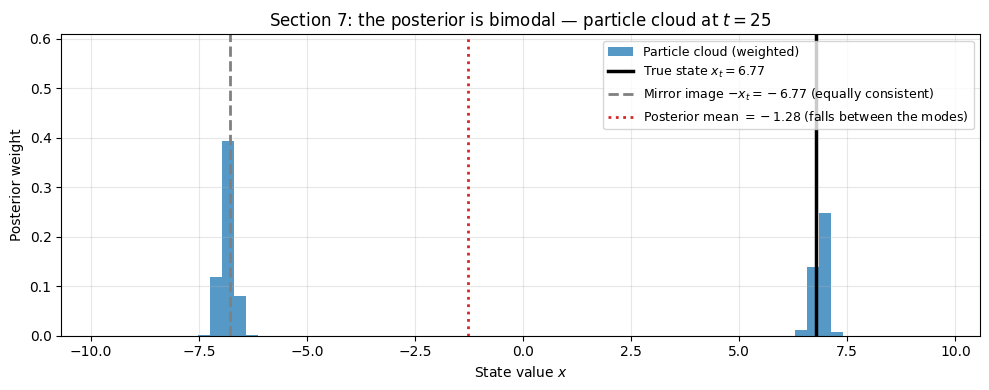

At t = 25: posterior weight on x > 0 is 0.406, on x < 0 is 0.594.
Two comparable modes -- the filter is representing genuine ambiguity, not failing.


In [10]:
# --- Look at the actual particle cloud at the step where |x_t| is largest ---
t_star = int(np.argmax(np.abs(x_nl)))

fig, ax = plt.subplots(figsize=(10, 4))
# Weighted histogram: each particle contributes its weight, not a count of 1.
counts, _, _ = ax.hist(parts[t_star], bins=70, weights=wts[t_star], color="tab:blue",
                       alpha=0.75, label="Particle cloud (weighted)")
ax.axvline(x_nl[t_star], color="black", lw=2.5,
           label=f"True state $x_t = {x_nl[t_star]:.2f}$")
ax.axvline(-x_nl[t_star], color="grey", lw=2, ls="--",
           label=f"Mirror image $-x_t = {-x_nl[t_star]:.2f}$ (equally consistent)")
ax.axvline(pf_nl_mean[t_star], color="tab:red", lw=2, ls=":",
           label=f"Posterior mean $= {pf_nl_mean[t_star]:.2f}$ (falls between the modes)")
# Headroom above the tallest bar so the legend does not sit on top of the modes.
ax.set_ylim(0, counts.max() * 1.55)
ax.set_title(f"Section 7: the posterior is bimodal — particle cloud at $t = {t_star}$")
ax.set_xlabel("State value $x$")
ax.set_ylabel("Posterior weight")
ax.legend(loc="upper right", fontsize=9)
plt.tight_layout()
plt.show()

# Quantify the two modes: how much posterior weight sits on each side of zero?
w_pos = wts[t_star][parts[t_star] > 0].sum()
print(f"At t = {t_star}: posterior weight on x > 0 is {w_pos:.3f}, "
      f"on x < 0 is {1 - w_pos:.3f}.")
print("Two comparable modes -- the filter is representing genuine ambiguity, not failing.")

**Conclusion.** The nonlinear example behaves as it did at $b = 0.9$, with one change worth noting.
Because the state now wanders further, the observation signal $x_t^2/20$ spans $0$ to $2.29$ instead
of $0$ to $0.94$ — so the fixed $R = 0.01$ chosen in Part 1 gives a **better** signal-to-noise ratio
here than it did there. The posterior is still bimodal, with weight $0.41$ and $0.59$ on either side
of zero at the step shown, and the filter still tracks $|x_t|$ well.

> **Compared with Part 1 ($b = 0.9$).**
>
> | | $b = 0.9$ | $b = 1$ |
> |---|---|---|
> | signal span $x^2/20$ | $0$ to $0.94$ | $0$ to $2.29$ |
> | RMSE of $E[|x_t|]$ | $0.4496$ | $0.4476$ |
> | do-nothing baseline | $1.0312$ | $1.6194$ |
> | improvement over baseline | $56\%$ | $72\%$ |
> | min ESS | $60.7$ | $35.7$ |
>
> **The improvement figures are not comparable.** The absolute error is the same ($0.448$ against
> $0.450$); what changed is the baseline, because a wandering state has more variation for a
> constant guess to miss. This is the same trap as the "$\%$ of signal" figure in Section 4 — any
> metric normalised by the state's own spread shifts at $b = 1$ for reasons that have nothing to do
> with the filter.

---
## Section 8 — Summary: does the threshold matter in 1D?

**Short answer: no, and the reason is instructive.**

### Everything of substance is unchanged

| | $b = 0.9$ | $b = 1$ |
|---|---|---|
| KF steady-state variance | $0.5974$ | $0.6180$ |
| mean PF–KF gap | $0.02721$ | $0.02688$ |
| fitted $O(1/\sqrt{N})$ slope | $-0.4934$ | $-0.4922$ |
| half-run error ratios | $1.019 / 1.102 / 1.074$ | $1.073 / 1.065 / 1.072$ |
| mean ESS | $531.1$ | $524.4$ |

Meanwhile the **state itself** grew by $63\%$ in spread and lost its stationary distribution
entirely. Removing the decay transformed what is being tracked and left the tracking untouched.

### Why: the observation does the work, not the decay

Part 1 explained its flat error curves by appeal to forgetting — $b < 1$ means old states, and
therefore old errors, decay geometrically. **That explanation is wrong, or at least incomplete.** At
$b = 1$ nothing decays and the error is just as flat.

What actually bounds the filter is that an observation arrives at every step. The variance recursion
$P \mapsto (1 - Ka)(b^2P + Q)$ has a bounded fixed point whether or not $b < 1$, because the update
always shrinks. The state may wander arbitrarily far; the filter's *uncertainty about where it is*
does not grow, because it is told where it is, every step, to within $\sqrt{R}$.

This is the one-dimensional, fully-observed case of the pattern found in
[`02b_md_dimension_rho1.ipynb`](02b_md_dimension_rho1.ipynb) and
[`05_f_stability_threshold.ipynb`](05_f_stability_threshold.ipynb): **crossing the threshold costs
nothing when the observations constrain the state, and costs a great deal when they do not.** At
$d = M = 1$ with $a = 1$ the state is as constrained as it can be, so this notebook is the most
benign case there is — which is exactly why it is worth having as the control.

### A caution about normalisation

Two figures in this notebook look like improvements and are not: the gap as a percentage of the
signal ($1.49\% \to 0.90\%$) and the nonlinear section's improvement over baseline ($56\% \to 72\%$).
Both have the state's own spread in the denominator, and that spread grew by $63\%$ while the
numerators stayed put. **Any metric normalised by the state is unreliable across the threshold.**
Normalising by the *posterior spread*, as Parts 2 onwards do with the relative gap, is unaffected.

### What this does not settle

- **$T = 100$ is short**, and at $b = 1$ the state has no stationary distribution, so the numbers
  here depend on the horizon in a way they did not at $b = 0.9$.
- **One dataset, and for Section 5 twenty seeds.** The half-run ratios are noisy.
- **Fully observed only.** The interesting case is where the observations do *not* constrain the
  state — see Part 2b for $M < d$, and Part 5 Section 9 for an unobserved explosive direction.